# 02 · Missing values and fraud distributions

**FinGuard AI, Phase 1.** Reads the joined tables saved by notebook 01.

Questions answered here:
1. How much is missing, and does it come in blocks?
2. Is missingness random, structural (driven by product) or informative (linked to fraud)?
3. How does fraud vary with amount, product, identity availability, email domain, device and card?

Rule used throughout: **compare within ProductCD before concluding anything.** Product
drives both missingness and fraud rate, so many apparent signals are product effects.

**Figures:** fig01, fig05, fig06, fig07, fig08, fig09, fig10, fig11, fig12.
**Tables:** missing_by_column, nan_blocks, informative_missingness, segment_fraud_rates.

In [1]:
import sys, pathlib, json
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from finguard import config
from finguard.data.ingest import load_table
from finguard.eda import missingness as M, figures as F, style as S
from finguard.features.normalize import amount_decimals

pd.set_option("display.max_columns", 30, "display.width", 160)
train, test = load_table("train"), load_table("test")
y = train[config.TARGET]
BASE = float(y.mean())
STATS = {}
print(train.shape, test.shape, f"base fraud rate {BASE:.3%}")

(590540, 438) (506691, 437) base fraud rate 3.499%


## 1. How much is missing
Missing share per feature column, in training and in the later (unlabelled) period.

In [2]:
miss = M.missing_by_column(train, test)
miss.to_csv(config.TABLE_DIR / "missing_by_column.csv")
STATS["cell_missing_rate"] = float(train[M.feature_columns(train)].isna().to_numpy().mean())
buckets = M.bucket_counts(miss.missing_train)
STATS["missing_buckets"] = buckets.to_dict()
print(f"{STATS['cell_missing_rate']:.1%} of all feature cells are empty")
display(buckets.to_frame("columns"))
miss.groupby("group").missing_train.agg(["count", "mean", "min", "max"]).round(3).sort_values("mean", ascending=False)

45.3% of all feature cells are empty


,columns
0%,18
(0-10%],92
(10-50%],108
(50-75%],6
(75-90%],196
(90-99%],3
>99%,9


,count,mean,min,max
group,,,,
id_01-38,38,0.848,0.756,0.992
DeviceType/Info,2,0.780,0.762,0.799
dist1-2,2,0.766,0.597,0.936
D1-15,15,0.582,0.002,0.934
M1-9,9,0.499,0.287,0.593
email,2,0.464,0.160,0.768
V1-339,339,0.430,0.000,0.861
addr1-2,2,0.111,0.111,0.111
card1-6,6,0.005,0.000,0.015


## 2. Missingness comes in blocks
Columns whose missing masks are identical form a block: the same rows lack all of them.
Each block is one piece of information ("this data source was absent"), not dozens.

In [3]:
blocks = M.nan_blocks(train)
STATS["n_blocks"], STATS["cols_in_blocks"] = len(blocks), int(blocks.n_cols.sum())
out = blocks.assign(columns=blocks["columns"].map(lambda c: ";".join(c)), groups=blocks["groups"].map(", ".join))
out.to_csv(config.TABLE_DIR / "nan_blocks.csv", index=False)
print(f"{len(blocks)} blocks cover {blocks.n_cols.sum()} columns")
blocks[["block", "first", "last", "n_cols", "groups", "missing_share", "fraud_rate_present", "fraud_rate_missing"]].round(4)

26 blocks cover 371 columns


,block,first,last,n_cols,groups,missing_share,fraud_rate_present,fraud_rate_missing
0,B01,V217,V278,46,[V1-339],0.7791,0.0781,0.0228
1,B02,V95,V137,43,[V1-339],0.0005,0.0350,0.0541
2,B03,V279,V321,32,[V1-339],0.0000,0.0350,0.1667
3,B04,V167,V216,31,[V1-339],0.7636,0.0791,0.0213
4,B05,V12,V34,23,[V1-339],0.1288,0.0326,0.0511
5,B06,V53,V74,22,[V1-339],0.1306,0.0315,0.0585
6,B07,V75,V94,20,[V1-339],0.1510,0.0327,0.0480
7,B08,V169,V210,19,[V1-339],0.7632,0.0792,0.0213
8,B09,V138,V163,18,[V1-339],0.8612,0.0445,0.0335
9,B10,V35,V52,18,[V1-339],0.2861,0.0346,0.0361


## 3. Is it random? No: it is structural
Missing share of each block by product. Whole blocks are 0% or 100% missing for some
products, so missingness is not MCAR. It is at best MAR given ProductCD.

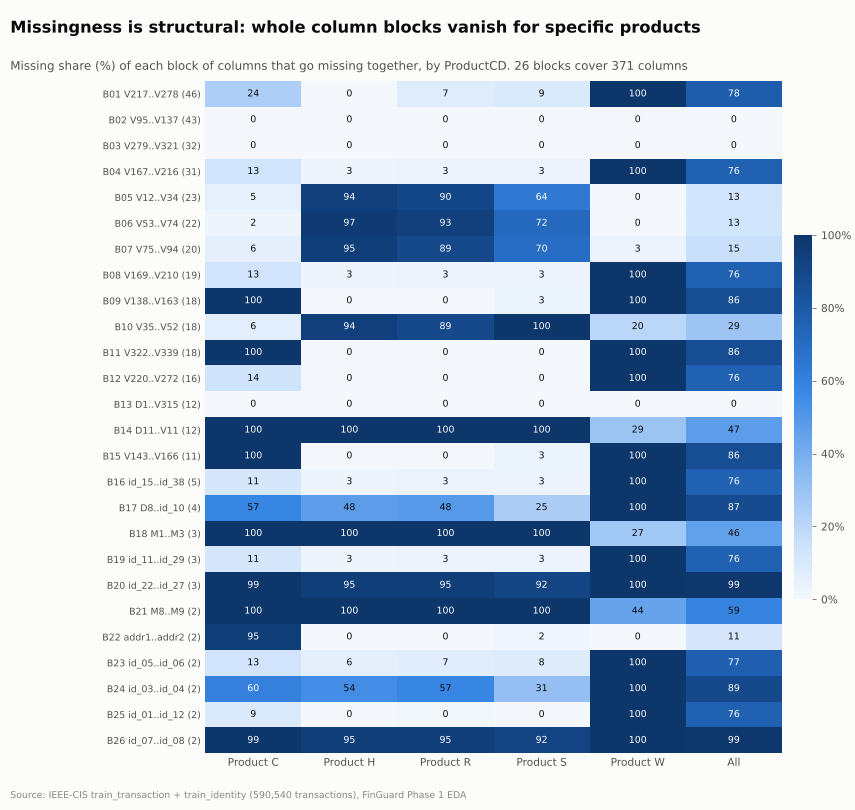

In [4]:
fig = F.fig05_block_missing_by_product(train, blocks)

## 4. Is it informative? Yes
Fraud rate when each block is present vs missing. If missingness carried no signal the
two dots would overlap. They do not, so imputing values would destroy information.

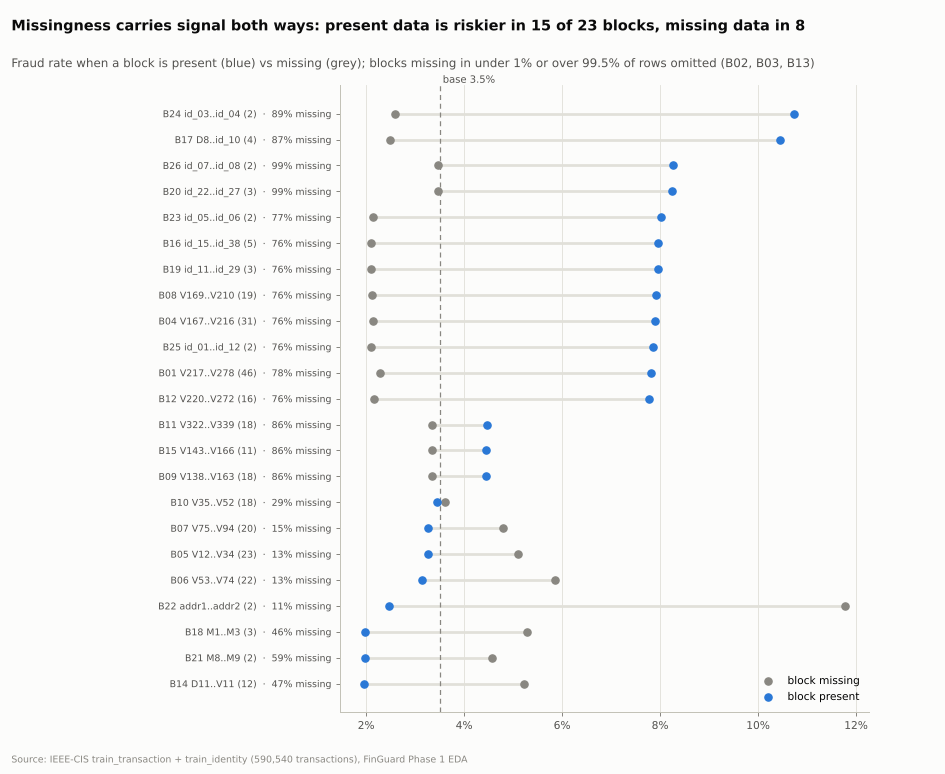

In [5]:
fig = F.fig06_block_presence_fraud(blocks, BASE)

In [6]:
info = M.informative_missingness(train)
info.to_csv(config.TABLE_DIR / "informative_missingness.csv", index=False)
ident = train.groupby("has_identity")[config.TARGET].agg(["size", "mean"])
STATS["fraud_with_identity"], STATS["fraud_without_identity"] = float(ident.loc[1, "mean"]), float(ident.loc[0, "mean"])
STATS["share_of_fraud_with_identity"] = float(train.loc[y == 1, "has_identity"].mean())
print(f"identity record present: {STATS['fraud_with_identity']:.2%} fraud | absent: {STATS['fraud_without_identity']:.2%}")
print(f"{STATS['share_of_fraud_with_identity']:.1%} of all frauds carry identity data")
info.head(12).round(4)

identity record present: 7.85% fraud | absent: 2.09%
54.8% of all frauds carry identity data


,column,group,missing_share,fraud_if_missing,fraud_if_present,auc_present_indicator
0,R_emaildomain,email,0.7675,0.0208,0.0818,0.6611
1,id_02,id_01-38,0.7615,0.0210,0.0797,0.6578
2,id_38,id_01-38,0.7613,0.0210,0.0796,0.6577
3,id_35,id_01-38,0.7613,0.0210,0.0796,0.6577
4,id_15,id_01-38,0.7613,0.0210,0.0796,0.6577
5,id_36,id_01-38,0.7613,0.0210,0.0796,0.6577
6,id_37,id_01-38,0.7613,0.0210,0.0796,0.6577
7,id_28,id_01-38,0.7613,0.0210,0.0796,0.6576
8,id_29,id_01-38,0.7613,0.0210,0.0796,0.6576
9,id_11,id_01-38,0.7613,0.0210,0.0796,0.6576


### Row-level view
Rows with the fewest missing fields are the riskiest: completeness is itself a signal.

In [7]:
nmiss = train[M.feature_columns(train)].isna().sum(axis=1)
dec = pd.qcut(nmiss, 10, duplicates="drop")
row_view = pd.DataFrame({"d": dec, "y": y, "n": nmiss}).groupby("d", observed=True).agg(
    rows=("y", "size"), fraud_rate=("y", "mean"), mean_missing_fields=("n", "mean")).round(4)
STATS["fraud_rate_least_missing_decile"] = float(row_view.fraud_rate.iloc[0])
row_view

,rows,fraud_rate,mean_missing_fields
d,,,
"(23.999, 109.0]",59383,0.0998,87.9759
"(109.0, 133.0]",61917,0.0641,128.0644
"(133.0, 208.0]",60513,0.0464,188.2185
"(208.0, 210.0]",73086,0.0162,209.7841
"(210.0, 211.0]",47757,0.0201,211.0000
"(211.0, 213.0]",62040,0.0135,212.4283
"(213.0, 227.0]",63055,0.0252,220.6862
"(227.0, 229.0]",47260,0.0217,228.8459
"(229.0, 232.0]",62416,0.0162,231.0309


### Missingness drifts
Missing rates change between training and the later period: a model that learned
"missing means X" will meet different proportions in production.

In [8]:
shift = miss.reindex(miss.missing_shift.abs().sort_values(ascending=False).index).head(10)
shift[["group", "missing_train", "missing_test", "missing_shift"]].round(3)

,group,missing_train,missing_test,missing_shift
D13,D1-15,0.895,0.756,-0.139
V41,V1-339,0.286,0.152,-0.134
V48,V1-339,0.286,0.152,-0.134
V35,V1-339,0.286,0.152,-0.134
V49,V1-339,0.286,0.152,-0.134
V38,V1-339,0.286,0.152,-0.134
V37,V1-339,0.286,0.152,-0.134
V39,V1-339,0.286,0.152,-0.134
V36,V1-339,0.286,0.152,-0.134
V46,V1-339,0.286,0.152,-0.134


## 5. Fraud by segment
Fraud rate with 95% Wilson intervals for the main readable segments.

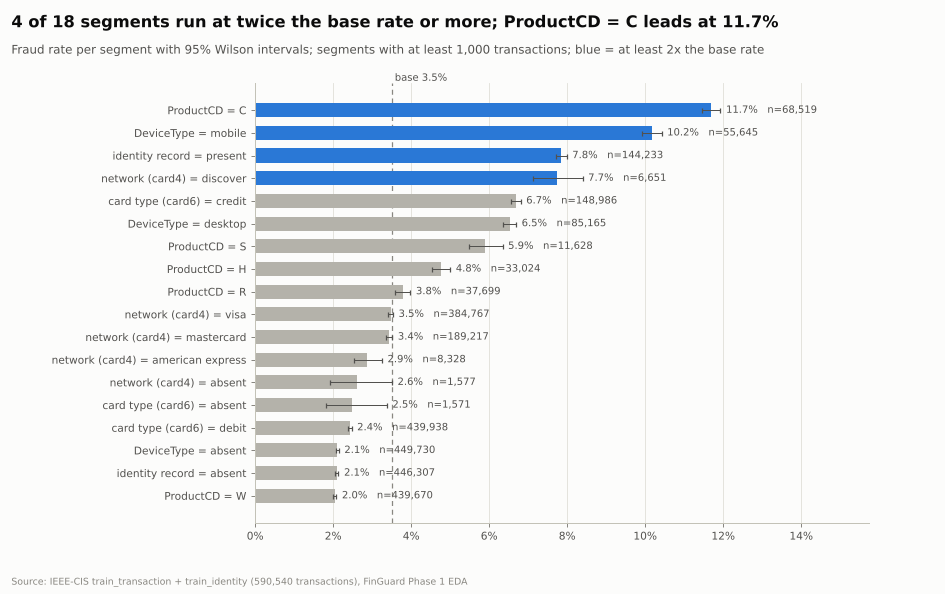

In [9]:
fig = F.fig01_fraud_rate_by_segment(train)

In [10]:
seg = []
for col in ["ProductCD", "card4", "card6", "DeviceType", "has_identity"]:
    t = S.rate_table(train[col], y).reset_index().rename(columns={"k": "value"})
    t.insert(0, "dimension", col)
    seg.append(t)
seg = pd.concat(seg).round(5)
seg.to_csv(config.TABLE_DIR / "segment_fraud_rates.csv", index=False)
prod = seg[seg.dimension == "ProductCD"].set_index("value")
STATS["product"] = {k: {"n": int(r.n), "rate": float(r.rate), "share_of_fraud": float(r.frauds / y.sum())} for k, r in prod.iterrows()}
prod

,dimension,n,frauds,rate,lo,hi
value,,,,,,
C,ProductCD,68519,8008,0.11687,0.11449,0.11930
H,ProductCD,33024,1574,0.04766,0.04542,0.05001
R,ProductCD,37699,1426,0.03783,0.03595,0.03980
S,ProductCD,11628,686,0.05900,0.05486,0.06343
W,ProductCD,439670,8969,0.02040,0.01999,0.02082


## 6. Amount
Amount alone carries almost no ranking signal; its relation to fraud is U-shaped.

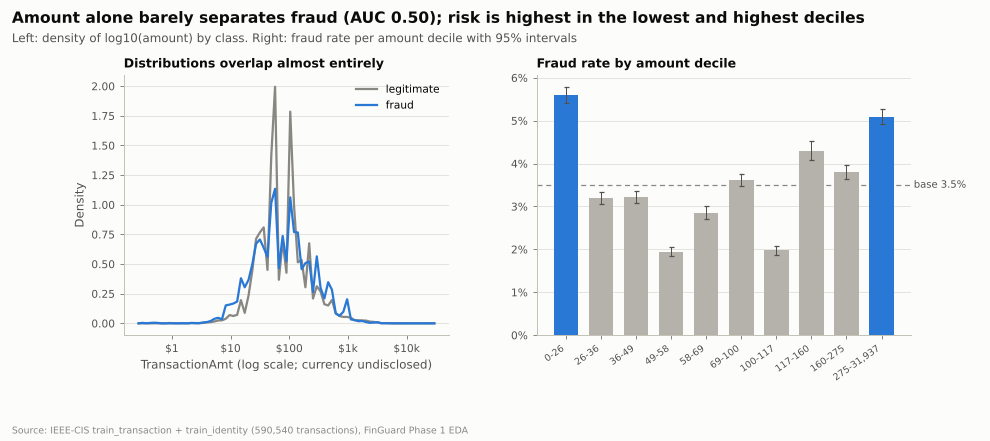

auc                 0.498
skew               14.374
skew_log            0.488
median_fraud       75.000
median_legit       68.500
p99              1104.000
max             31937.391

In [11]:
fig = F.fig07_amount(train)
from sklearn.metrics import roc_auc_score
amt = train.TransactionAmt
STATS["amount"] = {"auc": float(roc_auc_score(y, amt)), "skew": float(amt.skew()), "skew_log": float(np.log1p(amt).skew()),
                   "median_fraud": float(amt[y == 1].median()), "median_legit": float(amt[y == 0].median()),
                   "p99": float(amt.quantile(0.99)), "max": float(amt.max())}
pd.Series(STATS["amount"]).round(3)

### The decimals trap
Amounts with three decimals look like a strong signal overall. Holding ProductCD fixed
shows what is really going on.

decimals,0,1,2,3
ProductCD,,,,
C,35,478,6075,61931
H,33024,0,0,0
R,37699,0,0,0
S,11578,0,50,0
W,222677,22459,194532,2


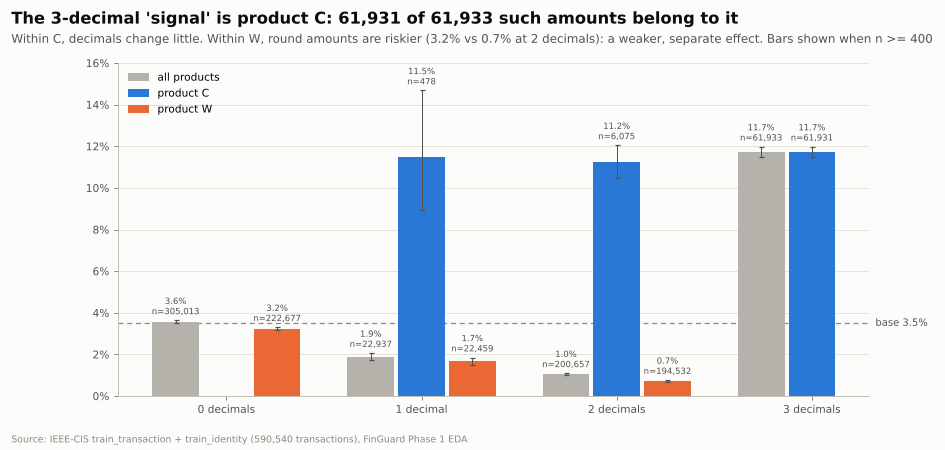

decimals: fraud rate,0,1,2,3
ProductCD,,,,
C,0.3429,0.1151,0.1123,0.1172
H,0.0477,NaN,NaN,NaN
R,0.0378,NaN,NaN,NaN
S,0.0593,NaN,0.0000,NaN
W,0.0323,0.0167,0.0072,0.0000


In [12]:
fig = F.fig08_decimals_within_product(train)
d = amount_decimals(train.TransactionAmt)
ct = pd.crosstab(train.ProductCD, d, values=y, aggfunc="mean").round(4)
STATS["three_decimal_share_product_C"] = float(((d == 3) & (train.ProductCD == "C")).sum() / (d == 3).sum())
display(pd.crosstab(train.ProductCD, d).rename_axis(columns="decimals"))
ct.rename_axis(columns="decimals: fraud rate")

## 7. Product and identity
Identity data is absent by design for product W. Within a product, does identity
presence still matter?

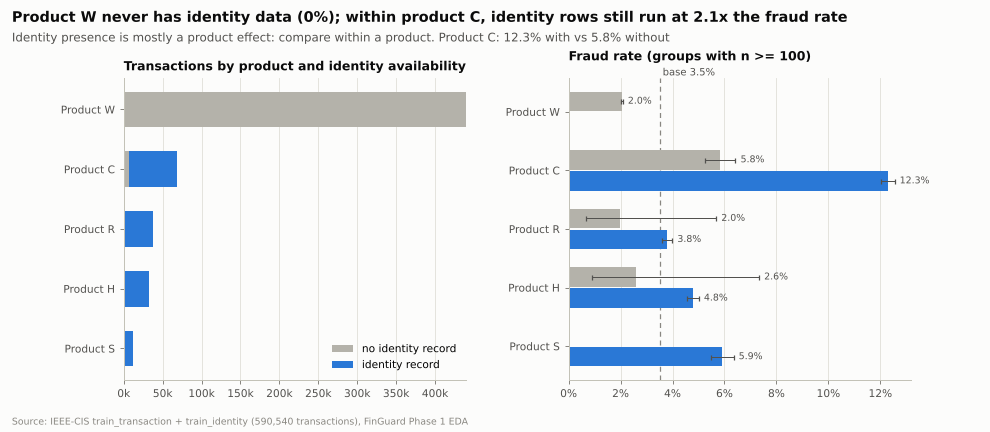

size    mean
ProductCD has_identity                
C         0               6327  0.0582
          1              62192  0.1228
H         0                116  0.0259
          1              32908  0.0477
R         0                151  0.0199
          1              37548  0.0379
S         0                 43  0.0465
          1              11585  0.0590
W         0             439670  0.0204

In [13]:
fig = F.fig09_product_identity(train)
pid = train.groupby(["ProductCD", "has_identity"])[config.TARGET].agg(["size", "mean"]).round(4)
STATS["product_C_identity"] = {"with": float(pid.loc[("C", 1), "mean"]), "without": float(pid.loc[("C", 0), "mean"])}
pid

## 8. Email domains
Readable, stable and directly explainable to an analyst.

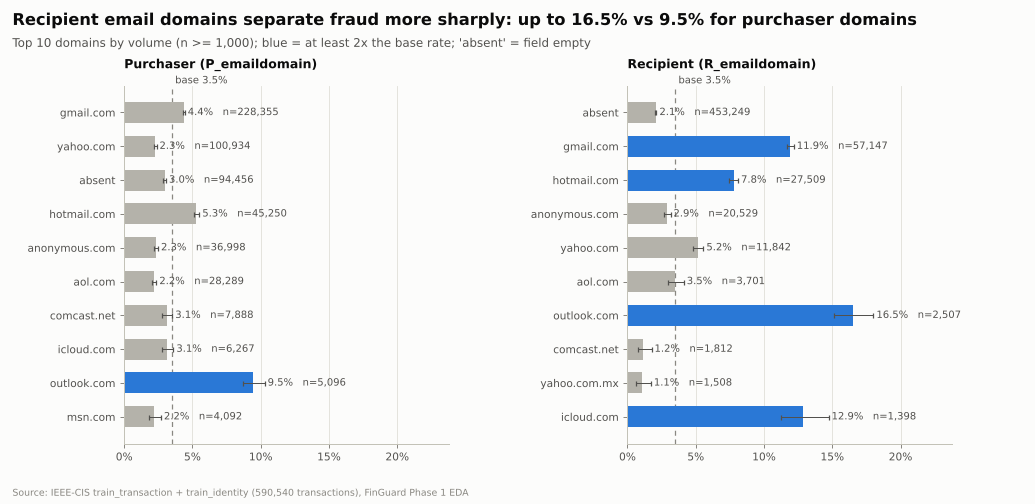

In [14]:
fig = F.fig10_email_domains(train)

## 9. Device: OS and browser families
Raw version strings are normalised to families (`finguard.features.normalize`) because
new versions appear every month.

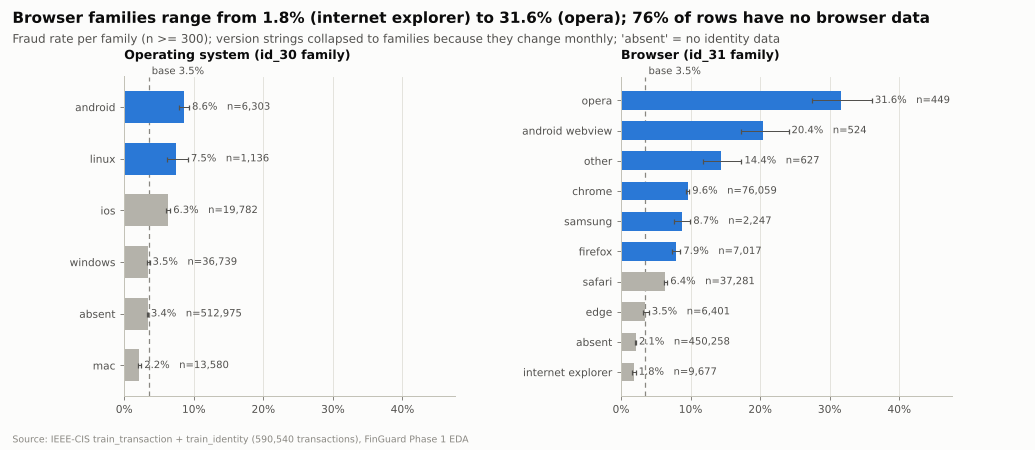

In [15]:
fig = F.fig11_os_browser(train)

In [16]:
dt = train[train.has_identity == 1]
pd.crosstab(dt.ProductCD, dt.DeviceType.fillna("absent"), values=dt[config.TARGET], aggfunc="mean").round(4).rename_axis(
    columns="DeviceType: fraud rate (rows with identity)")

DeviceType: fraud rate (rows with identity),absent,desktop,mobile
ProductCD,,,
C,0.0391,0.1181,0.1314
H,0.0099,0.0434,0.0563
R,0.0161,0.0223,0.0747
S,0.1104,0.0444,0.1162


## 10. Card network and type

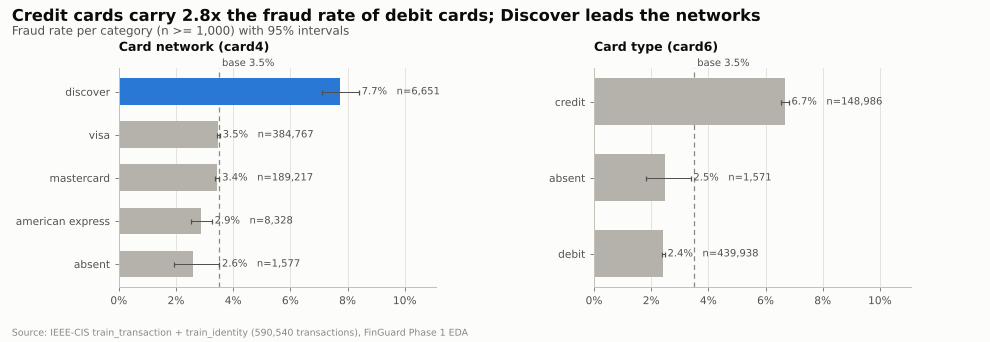

In [17]:
fig = F.fig12_card_network_type(train)

In [18]:
(config.TABLE_DIR / "phase1_stats_02.json").write_text(json.dumps(STATS, indent=2, default=float))
print(json.dumps({k: STATS[k] for k in ["cell_missing_rate", "n_blocks", "cols_in_blocks", "fraud_with_identity",
                                        "fraud_without_identity", "three_decimal_share_product_C", "product_C_identity"]}, indent=1, default=float))

{
 "cell_missing_rate": 0.4528304955351599,
 "n_blocks": 26,
 "cols_in_blocks": 371,
 "fraud_with_identity": 0.07847025299342036,
 "fraud_without_identity": 0.020938501972857248,
 "three_decimal_share_product_C": 0.999967707038251,
 "product_C_identity": {
  "with": 0.1228,
  "without": 0.0582
 }
}


## Findings
* **45% of feature cells are empty**, concentrated in blocks: 371 columns fall into 26 blocks.
* **Missingness is structural, not random.** Product W never has identity data; the
  M-columns exist almost only for W; address codes are missing for 95% of product C.
* **Missingness is informative.** Transactions with identity data are about 3.8x riskier;
  the least-missing decile of rows has the highest fraud rate. Missing values must stay
  visible to the model (NaN for trees, indicators for linear models), never be imputed away.
* **Amount alone does not rank fraud** (AUC about 0.50); risk is U-shaped across deciles.
* **The 3-decimal signal is product C in disguise**: almost all 3-decimal amounts are
  product C, where fraud is 11-12% whatever the decimals.
* **Product C** carries the highest fraud rate (11.7%) and 39% of all fraud; **credit**
  cards about 2.7x debit; recipient email domains separate fraud more sharply than
  purchaser domains; mobile and some browser families stand out once versions are normalised.
* Device and identity effects must be read **within product**, because identity data
  exists only for non-W products.